In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate project root
root = Path.cwd()

if root.name == "notebooks":
    root = root.parent

# Load asset returns
file_path = root / "data" / "processed" / "asset_returns.csv"

df_assets = pd.read_csv(file_path)

print("Shape:", df_assets.shape)
print("Columns:", df_assets.columns.tolist())

display(df_assets.head())


Shape: (4232, 6)
Columns: ['Date', 'SPY', 'QQQ', 'IWM', 'EFA', 'EEM']


,Date,SPY,QQQ,IWM,EFA,EEM
0,2010-01-05,0.002647,0.000000,-0.003439,0.000881,0.007258
1,2010-01-06,0.000704,-0.006032,-0.000941,0.004227,0.002092
2,2010-01-07,0.004221,0.000650,0.007378,-0.003858,-0.005799
3,2010-01-08,0.003328,0.008230,0.005454,0.007922,0.007932
4,2010-01-11,0.001397,-0.004082,-0.004029,0.008210,-0.002083


In [2]:
# Step 3: Estimate mean vector and covariance matrix

tickers = ["SPY", "QQQ", "IWM", "EFA", "EEM"]

# Select the first 500 trading days
window = 500
first_window = df_assets[tickers].iloc[:window]

# Calculate daily mean returns
mean_vector = first_window.mean()

# Calculate daily covariance matrix
cov_matrix = first_window.cov()

print("Mean Vector (Daily Returns):")
display(mean_vector.to_frame(name="Mean Return"))

print("Covariance Matrix (Daily):")
display(cov_matrix)

Mean Vector (Daily Returns):


,Mean Return
SPY,0.000385
QQQ,0.000514
IWM,0.000528
EFA,-0.000017
EEM,0.000011


Covariance Matrix (Daily):


,SPY,QQQ,IWM,EFA,EEM
SPY,0.000169,0.000167,0.000223,0.000209,0.000218
QQQ,0.000167,0.000186,0.000225,0.000203,0.000214
IWM,0.000223,0.000225,0.000325,0.000270,0.000288
EFA,0.000209,0.000203,0.000270,0.000296,0.000291
EEM,0.000218,0.000214,0.000288,0.000291,0.000338


In [3]:
# Step 4: Portfolio mean and volatility

weights = np.array([0.40, 0.25, 0.15, 0.10, 0.10])

# Portfolio expected daily return
portfolio_mean = weights @ mean_vector.to_numpy()

# Portfolio daily variance
portfolio_variance = (
    weights @ cov_matrix.to_numpy() @ weights
)

# Portfolio daily volatility
portfolio_volatility = np.sqrt(portfolio_variance)

print(f"Portfolio Mean: {portfolio_mean:.4%}")
print(f"Portfolio Variance: {portfolio_variance:.8f}")
print(f"Portfolio Volatility: {portfolio_volatility:.4%}")

Portfolio Mean: 0.0361%
Portfolio Variance: 0.00020695
Portfolio Volatility: 1.4386%


In [4]:
# Step 4B: Validate portfolio volatility

# Calculate portfolio returns directly
direct_portfolio_returns = first_window @ weights

# Calculate sample standard deviation
direct_volatility = direct_portfolio_returns.std(ddof=1)

print(f"Covariance Method: {portfolio_volatility:.6%}")
print(f"Direct Method:     {direct_volatility:.6%}")

print(
    "Results Match:",
    np.isclose(portfolio_volatility, direct_volatility)
)

Covariance Method: 1.438582%
Direct Method:     1.438582%
Results Match: True


In [5]:
from scipy.stats import norm

# Standard normal quantiles
z_95 = norm.ppf(0.95)
z_99 = norm.ppf(0.99)

# Parametric VaR
param_var_95 = -portfolio_mean + z_95 * portfolio_volatility
param_var_99 = -portfolio_mean + z_99 * portfolio_volatility

print(f"95% Parametric VaR: {param_var_95:.4%}")
print(f"99% Parametric VaR: {param_var_99:.4%}")

95% Parametric VaR: 2.3302%
99% Parametric VaR: 3.3106%


In [6]:
# Step 6: Parametric Expected Shortfall

param_es_95 = (
    -portfolio_mean
    + portfolio_volatility * norm.pdf(z_95) / (1 - 0.95)
)

param_es_99 = (
    -portfolio_mean
    + portfolio_volatility * norm.pdf(z_99) / (1 - 0.99)
)

print(f"95% Parametric ES: {param_es_95:.4%}")
print(f"99% Parametric ES: {param_es_99:.4%}")

95% Parametric ES: 2.9313%
99% Parametric ES: 3.7980%


In [9]:
import sys

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.parametric_var import parametric_var, parametric_es

print(
    f"95% Parametric VaR: "
    f"{parametric_var(portfolio_mean, portfolio_volatility, 0.95):.4%}"
)

print(
    f"99% Parametric VaR: "
    f"{parametric_var(portfolio_mean, portfolio_volatility, 0.99):.4%}"
)

print(
    f"95% Parametric ES: "
    f"{parametric_es(portfolio_mean, portfolio_volatility, 0.95):.4%}"
)

print(
    f"99% Parametric ES: "
    f"{parametric_es(portfolio_mean, portfolio_volatility, 0.99):.4%}"
)

95% Parametric VaR: 2.3302%
99% Parametric VaR: 3.3106%
95% Parametric ES: 2.9313%
99% Parametric ES: 3.7980%


In [10]:

# Step 11: Rolling Parametric VaR / ES Forecast

window = 500

forecast_results = []

for t in range(window, len(df_assets)):

    # Use only the previous 500 trading days
    historical_window = df_assets[tickers].iloc[t-window:t]

    # Estimate mean vector and covariance matrix
    mu = historical_window.mean().to_numpy()
    sigma = historical_window.cov().to_numpy()

    # Calculate portfolio mean and variance
    mu_p = weights @ mu
    var_p = weights @ sigma @ weights

    # Portfolio daily volatility
    vol_p = np.sqrt(var_p)

    # Calculate Parametric VaR and ES
    var_95 = parametric_var(mu_p, vol_p, 0.95)
    var_99 = parametric_var(mu_p, vol_p, 0.99)

    es_95 = parametric_es(mu_p, vol_p, 0.95)
    es_99 = parametric_es(mu_p, vol_p, 0.99)

    # Store forecast results
    forecast_results.append({
        "Date": df_assets["Date"].iloc[t],
        "actual_return": float(
            df_assets[tickers].iloc[t] @ weights
        ),
        "portfolio_mean": mu_p,
        "portfolio_volatility": vol_p,
        "var_95": var_95,
        "var_99": var_99,
        "es_95": es_95,
        "es_99": es_99
    })

parametric_rolling_df = pd.DataFrame(forecast_results)

print("Forecast observations:", len(parametric_rolling_df))

display(parametric_rolling_df.head())


Forecast observations: 3732


,Date,actual_return,portfolio_mean,portfolio_volatility,var_95,var_99,es_95,es_99
0,2011-12-28,-0.014352,0.000361,0.014386,0.023302,0.033106,0.029313,0.037980
1,2011-12-29,0.010431,0.000329,0.014401,0.023358,0.033172,0.029375,0.038052
2,2011-12-30,-0.002924,0.000352,0.014408,0.023347,0.033166,0.029367,0.038048
3,2012-01-03,0.019430,0.000342,0.014408,0.023358,0.033177,0.029378,0.038059
4,2012-01-04,-0.000290,0.000369,0.014432,0.023369,0.033204,0.029399,0.038094


In [11]:
print("Total forecasts:", len(parametric_rolling_df))

print(
    "First forecast:",
    parametric_rolling_df["Date"].iloc[0]
)

print(
    "Last forecast:",
    parametric_rolling_df["Date"].iloc[-1]
)

first_forecast = parametric_rolling_df.iloc[0]

print(f"First 95% VaR: {first_forecast['var_95']:.4%}")
print(f"First 99% VaR: {first_forecast['var_99']:.4%}")
print(f"First 95% ES: {first_forecast['es_95']:.4%}")
print(f"First 99% ES: {first_forecast['es_99']:.4%}")

print("\nMissing Values:")
print(parametric_rolling_df.isna().sum())

Total forecasts: 3732
First forecast: 2011-12-28
Last forecast: 2026-10-30
First 95% VaR: 2.3302%
First 99% VaR: 3.3106%
First 95% ES: 2.9313%
First 99% ES: 3.7980%

Missing Values:
Date                    0
actual_return           0
portfolio_mean          0
portfolio_volatility    0
var_95                  0
var_99                  0
es_95                   0
es_99                   0
dtype: int64


In [12]:
# Step 13: Validate alignment with Historical Simulation

historical_path = (
    root / "results" / "historical_var_es_forecasts.csv"
)

historical_df = pd.read_csv(historical_path)

# Normalize date formats
historical_dates = pd.to_datetime(historical_df["Date"])
parametric_dates = pd.to_datetime(parametric_rolling_df["Date"])

# Check forecast dates
assert historical_dates.reset_index(drop=True).equals(
    parametric_dates.reset_index(drop=True)
)

# Check realized portfolio returns
assert np.allclose(
    historical_df["actual_return"].to_numpy(),
    parametric_rolling_df["actual_return"].to_numpy(),
    rtol=0,
    atol=1e-10
)

print("Forecast dates match: True")
print("Actual portfolio returns match: True")

Forecast dates match: True
Actual portfolio returns match: True


In [13]:
# Step 14: Parametric VaR exceptions

parametric_rolling_df["actual_loss"] = (
    -parametric_rolling_df["actual_return"]
)

parametric_rolling_df["exception_95"] = (
    parametric_rolling_df["actual_loss"]
    > parametric_rolling_df["var_95"]
)

parametric_rolling_df["exception_99"] = (
    parametric_rolling_df["actual_loss"]
    > parametric_rolling_df["var_99"]
)

print(
    "95% Exceptions:",
    parametric_rolling_df["exception_95"].sum()
)

print(
    "95% Exception Rate:",
    f"{parametric_rolling_df['exception_95'].mean():.2%}"
)

print(
    "99% Exceptions:",
    parametric_rolling_df["exception_99"].sum()
)

print(
    "99% Exception Rate:",
    f"{parametric_rolling_df['exception_99'].mean():.2%}"
)

95% Exceptions: 181
95% Exception Rate: 4.85%
99% Exceptions: 83
99% Exception Rate: 2.22%


In [14]:
# Step 15: Validate rolling forecasts

assert len(parametric_rolling_df) == 3732

assert parametric_rolling_df["Date"].is_unique

assert np.isfinite(
    parametric_rolling_df[
        ["portfolio_mean", "portfolio_volatility",
         "var_95", "var_99", "es_95", "es_99"]
    ].to_numpy()
).all()

assert (
    parametric_rolling_df["portfolio_volatility"] >= 0
).all()

assert (
    parametric_rolling_df["var_99"]
    >= parametric_rolling_df["var_95"]
).all()

assert (
    parametric_rolling_df["es_95"]
    >= parametric_rolling_df["var_95"]
).all()

assert (
    parametric_rolling_df["es_99"]
    >= parametric_rolling_df["var_99"]
).all()

print("All Parametric Rolling Forecast Checks Passed!")

All Parametric Rolling Forecast Checks Passed!


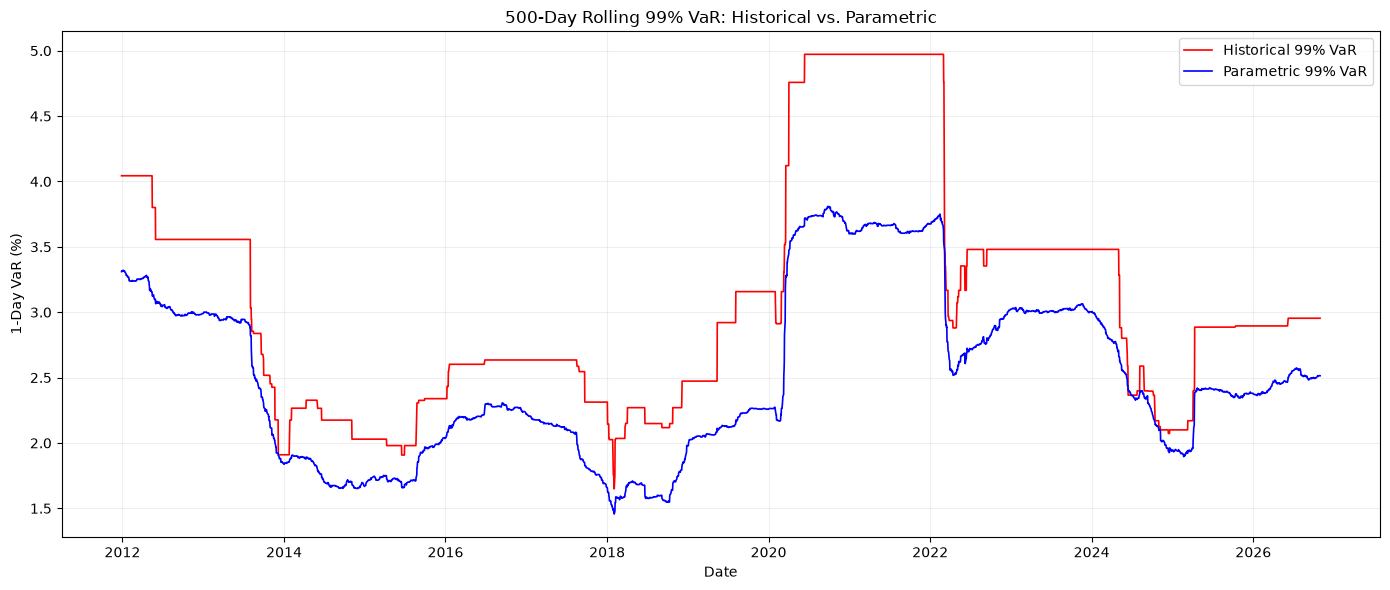

In [15]:
# Step 16: Compare Rolling VaR Forecasts

import matplotlib.pyplot as plt

# Align dates
parametric_rolling_df["Date"] = pd.to_datetime(
    parametric_rolling_df["Date"]
)

historical_df["Date"] = pd.to_datetime(
    historical_df["Date"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    historical_df["Date"],
    historical_df["var_99"] * 100,
    label="Historical 99% VaR",
    color="red",
    linewidth=1.2
)

plt.plot(
    parametric_rolling_df["Date"],
    parametric_rolling_df["var_99"] * 100,
    label="Parametric 99% VaR",
    color="blue",
    linewidth=1.2
)

plt.title("500-Day Rolling 99% VaR: Historical vs. Parametric")
plt.xlabel("Date")
plt.ylabel("1-Day VaR (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [17]:
# Step 17: Export Parametric VaR / ES Forecasts

output_dir = root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "parametric_var_es_forecasts.csv"
)

parametric_rolling_df.to_csv(
    output_path,
    index=False
)

print("Saved to:", output_path)
print("Rows:", len(parametric_rolling_df))

Saved to: /Users/tzuling/Desktop/HW/self project/portfolio-var-es-backtesting/results/parametric_var_es_forecasts.csv
Rows: 3732
